In [50]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import pandas as pd
import xarray as xr

start_year = 1974
end_year = 2013
n_year = end_year - start_year + 1
len_year = 92 * 24

ds = xr.open_dataset("wgbt_era5_Paris_1974-2023jja.nc")
ts_wbgt = ds.wbgt.values.ravel().astype(np.float64)
ts_date = pd.DatetimeIndex(ds.time.values)
ts_tas = xr.open_dataset("ta_era5_Paris_1974-2023jja.nc").t2m.values.ravel().astype(np.float64) - 273.15
ts_mort = np.load("mortality.npy").astype(np.float64)[24*92:-4*92]

mask = (ts_date.year >= start_year) & (ts_date.year <= end_year)
ts_wbgt = ts_wbgt[mask]
ts_tas = ts_tas[mask]
ts_date = ts_date[mask]

def random_walk(n):
    steps = np.random.choice([-1, 1], size=n)
    return np.cumsum(steps)


daily = False
agg = "max"
ts_date_days = pd.date_range('01-Jan-1974', '31-Dec-2023', freq='D')
ts_date_days = ts_date_days[ts_date_days.month.isin([6, 7, 8])]

if daily:
    len_year = 92
    ts_date = ts_date_days
    if agg == "max":
        fnc = np.max
    elif agg == "min":
        fnc = np.min
    ts_tas = np.array([fnc(ts_tas[i*24:(i+1)*24]) for i in range(len(ts_tas)//24)])
    ts_wbgt = np.array([fnc(ts_wbgt[i*24:(i+1)*24]) for i in range(len(ts_wbgt)//24)])


In [51]:
time_series_path = "../Data/SST/mediterranean_average_processed.npy"
time_series_dates_path = "../Data/SST/mediterranean_average_processed_dates.npy"
start_year = 2020
end_year = 2023

ts = np.load(time_series_path).astype(np.float64) - 273.15
ts_date = pd.DatetimeIndex(np.load(time_series_dates_path))

mask = (ts_date.year >= start_year) & (ts_date.year <= end_year)
ts_date = ts_date[mask]
ts_sst = ts[mask]




In [52]:
df = pd.read_csv("../Data/SST/norm.daily.aao.cdas.z700.19790101_current.csv")
ts_aao = df["aao_index_cdas"]
mask = (df.year >= 2020) & (df.year <=2023)
ts_aao = ts_aao[mask]

In [53]:
import numpy as np
import pandas as pd

# Assuming ts_date is a Pandas Series of datetime and ts_sst is a Pandas Series of SST values
df = pd.DataFrame({'date': ts_date, 'sst': ts_sst})

# Extract day-of-year (DOY)
df['doy'] = df['date'].dt.dayofyear

# Compute Climatology: Mean SST for each DOY
climatology = df.groupby('doy')['sst'].mean()

# Compute Anomalies: Subtract climatological mean from SST values
df['sst_anomaly'] = df.apply(lambda row: row['sst'] - climatology.loc[row['doy']], axis=1)

# Resulting time series of SST anomalies
ts_sst_anomaly = df['sst_anomaly'].to_numpy()

In [54]:

# Generate synthetic time series data
np.random.seed(42)
w = 24  * 1

# Example time series
X = ts_tas
Y = ts_wbgt
ts_date = pd.DatetimeIndex(ds.time.values)


T = len(X)



# Function to compute sliding window correlation
def sliding_window_correlation(X, Y, w):
    correlations = np.zeros(len(X)-w)
    for i,t in enumerate(range(w, T)):
        lags = [t] #range(max(t-1,w), min(t+2,T))
        x_window = X[t-w:t]
        mcorr = -2.0
        for tp in lags:
            y_window = Y[tp-w:tp]
            corr, _ = pearsonr(x_window, y_window)
            mcorr = max(mcorr, corr)
        correlations[i] = mcorr
    return correlations

def sliding_window_similarity(X, Y, w):
    correlations = np.zeros(len(X)-w)
    for i,t in enumerate(range(w, T)):
        lags = [t] #range(max(t-1,w), min(t+2,T))
        x_window = X[t-w:t]
        nx = np.linalg.norm(x_window)
        mcorr = -2.0
        for tp in lags:
            y_window = Y[tp-w:tp]
            
            ny = np.linalg.norm(y_window)
            corr = np.dot(x_window,y_window) / (nx*ny) 
            mcorr = max(mcorr, corr)

        correlations[i] = mcorr
    return correlations
    
def sliding_window_distance(X, Y, w):
    distances = np.zeros(len(X)-w)
    for i,t in enumerate(range(w, T)):
        lags = [t] 
        x_window = X[t-w:t]
        nx = np.linalg.norm(x_window)
        dist = -2.0
        for tp in lags:
            y_window = Y[tp-w:tp]
            
            d = np.linalg.norm(x_window-y_window)
            dist = max(dist, d)

        distances[i] = dist
    return distances

# Function to compute ICD
def compute_icd(correlations, alpha=0.9):
    T = len(correlations)
    icd_values = []
    expected_corr = np.zeros(T)
    variance = np.zeros(T)

    for t in range(1, T):
        if t == 1:
            expected_corr[t] = correlations[0]
        else:
            expected_corr[t] = alpha * correlations[t-1] + (1 - alpha) * expected_corr[t-1]

        # Update variance
        if t >= T:
            variance[t] = variance[t-1] + (correlations[t] - expected_corr[t])**2 - (correlations[t-T] - expected_corr[t-T])**2
        else:
            variance[t] = variance[t-1] + (correlations[t] - expected_corr[t])**2

        std_dev = np.sqrt(variance[t] / min(t, T))

        if std_dev == 0:
            icd = 0  # Avoid division by zero
        else:
            icd = abs(correlations[t] - expected_corr[t]) / std_dev

        icd_values.append(icd)

    return icd_values

# Compute sliding window correlation
correlations = sliding_window_correlation(X, Y, w)
similarities = sliding_window_similarity(X, Y, w)
distances = sliding_window_distance(X, Y, w)
"""
correlations = filter_out_overlap(correlations, 24*92, w)
similarities = filter_out_overlap(similarities, 24*92, w)
"""

# Compute ICD
icd_values = compute_icd(correlations)

In [55]:
def filter_out_overlap(x, period, w):
    for i in range(len(x) // period):
        start = (i+1) * period - w + 1
        
        x[start:start+w] = np.nan
    return x

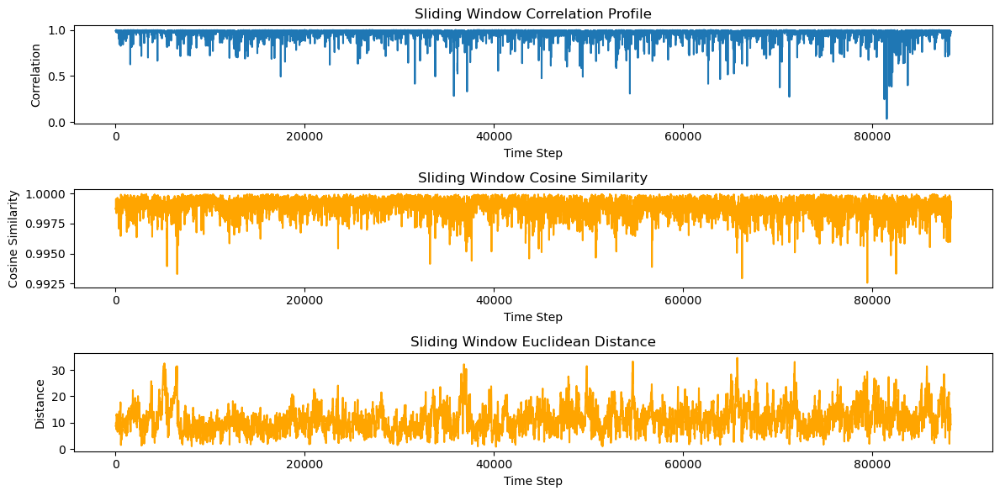

In [56]:
# Plot results
time_steps = np.arange(w, T)

plt.figure(figsize=(12, 6))

plt.subplot(3, 1, 1)
plt.plot(time_steps, correlations, label='Sliding Window Correlation')
plt.title('Sliding Window Correlation Profile')
plt.xlabel('Time Step')
plt.ylabel('Correlation')

plt.subplot(3, 1, 2)
plt.plot(time_steps, similarities, label='Cosine Simila', color='orange')
plt.title('Sliding Window Cosine Similarity')
plt.xlabel('Time Step')
plt.ylabel('Cosine Similarity')

plt.subplot(3, 1, 3)
plt.plot(time_steps, distances, color='orange')
plt.title('Sliding Window Euclidean Distance')
plt.xlabel('Time Step')
plt.ylabel('Distance')

"""
plt.subplot(2, 1, 2)
plt.plot(time_steps[:-1], icd_values, label='ICD', color='orange')
plt.title('Index of Correlation Deviation (ICD)')
plt.xlabel('Time Step')
plt.ylabel('ICD')
plt.legend()
"""
plt.tight_layout()
plt.show()


In [57]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots



# Create subplots
fig = make_subplots(rows=3, cols=1, shared_xaxes=True, subplot_titles=[
    "Sliding Window Correlation Profile", 
    "Sliding Window Cosine Similarity",
    "Time Series X and Y"
])

# Add traces
fig.add_trace(go.Scatter(x=time_steps, y=correlations, mode='lines', name='Sliding Window Correlation'), row=1, col=1)
fig.add_trace(go.Scatter(x=time_steps, y=similarities, mode='lines', name='Cosine Similarity', line=dict(color='orange')), row=2, col=1)
fig.add_trace(go.Scatter(x=time_steps, y=(X-np.nanmin(X))/(np.nanmax(X)-np.nanmin(X)), mode='lines', name='X', line=dict(color='blue')), row=3, col=1)
fig.add_trace(go.Scatter(x=time_steps, y=(Y-np.nanmin(Y))/(np.nanmax(Y)-np.nanmin(Y)), mode='lines', name='Y', line=dict(color='red')), row=3, col=1)

# Update layout for synchronization
fig.update_layout(height=800, width=1200, title_text="Synchronized Subplots", hovermode='x unified', showlegend=False)
fig.show()


In [58]:
def k_minimum_indices(arr, k):
    valid_indices = np.where(~np.isnan(arr))[0]
    valid_values = arr[valid_indices]
    k_smallest_indices = np.argsort(valid_values)[:k]
    
    return valid_indices[k_smallest_indices]

In [59]:
len(ts_date)

110400

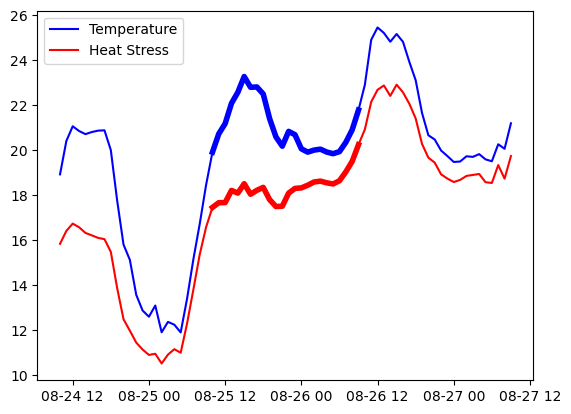

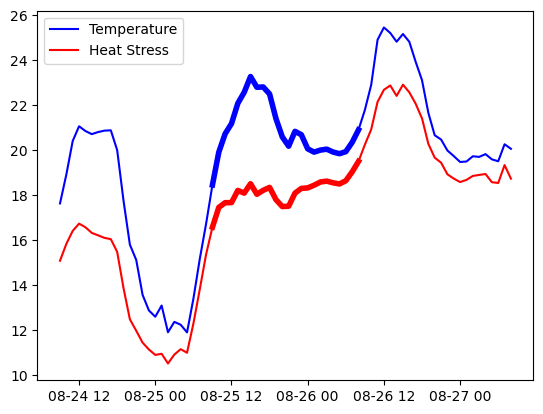

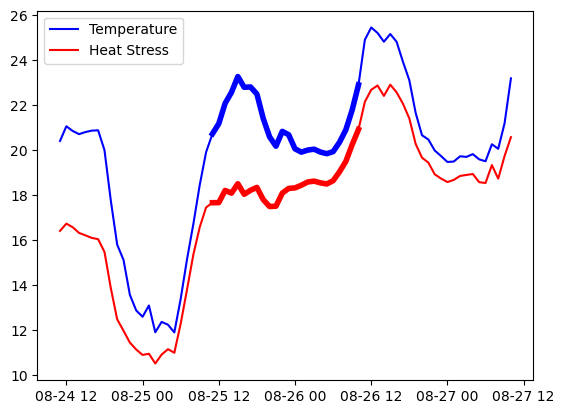

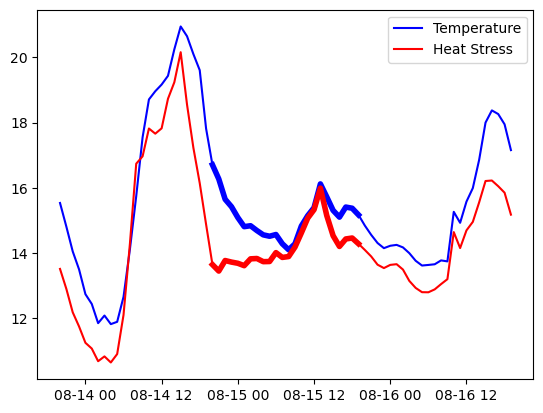

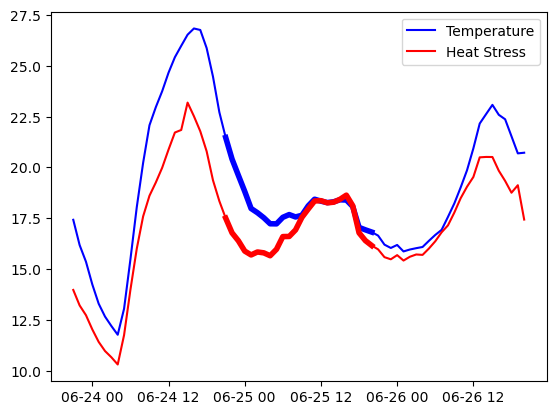

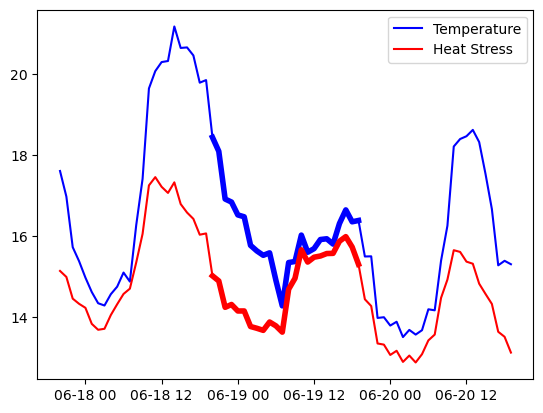

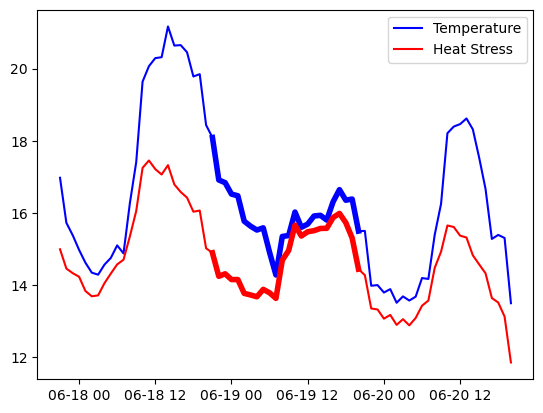

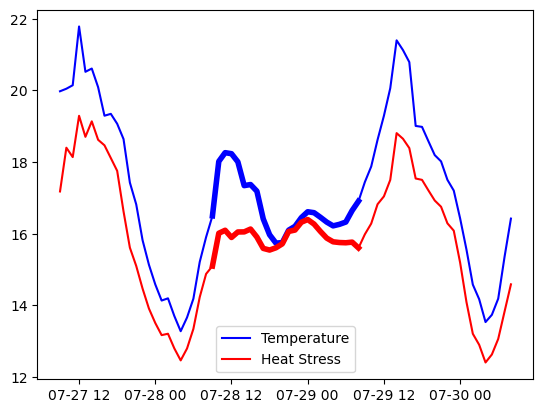

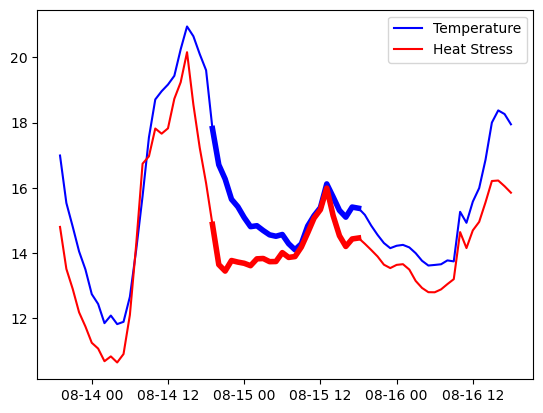

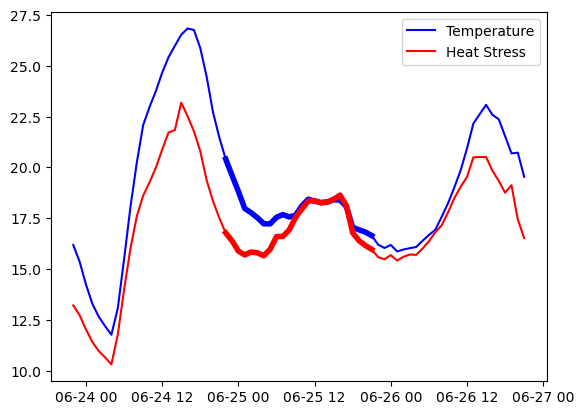

In [60]:
k = 10
idx = k_minimum_indices(correlations, k)
ind = np.nanargmin(correlations)

for i in range(k):
    ind = idx[i]
    
    x = np.arange(ind-24, ind+24+w)
    x1 = np.arange(ind, ind+w)
    
    x = ts_date[ind-24:ind+w+24]
    x1 = ts_date[ind:ind+w]
    
    plt.plot(x, ts_tas[ind-24:ind+w+24], color="blue", label="Temperature")
    plt.plot(x, ts_wbgt[ind-24:ind+w+24], color="red", label="Heat Stress")
    
    plt.plot(x1, ts_tas[ind:ind+w], color="blue", lw=4)
    plt.plot(x1, ts_wbgt[ind:ind+w], color="red", lw=4)
    plt.legend()
    plt.show()

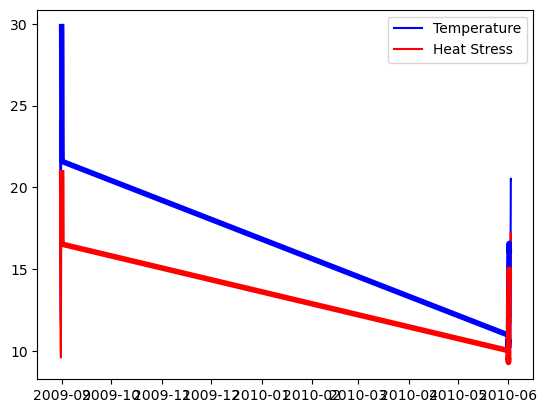

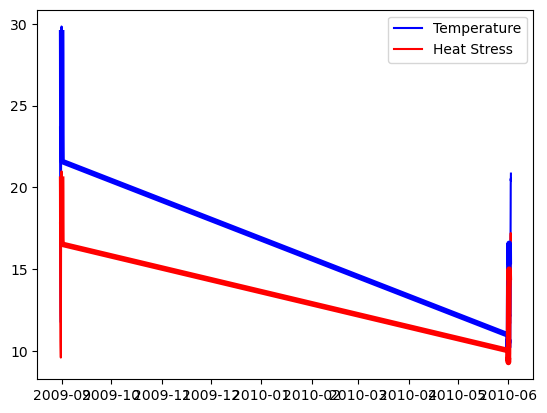

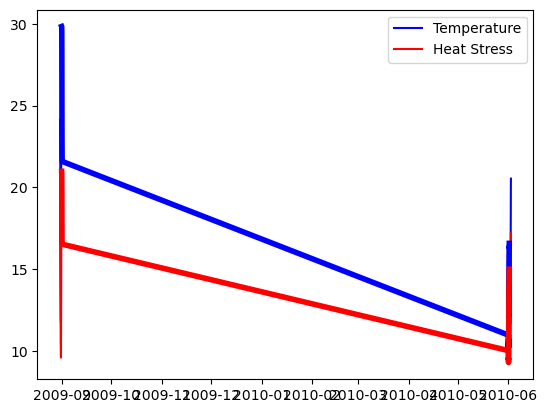

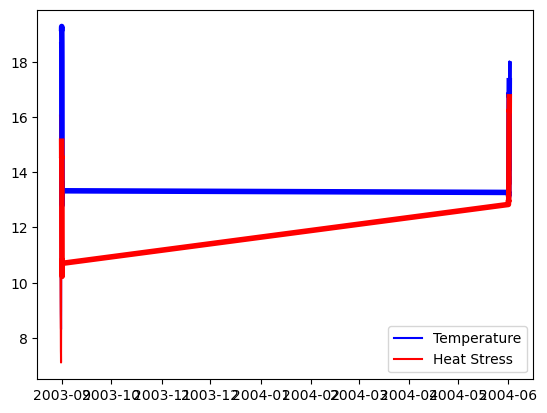

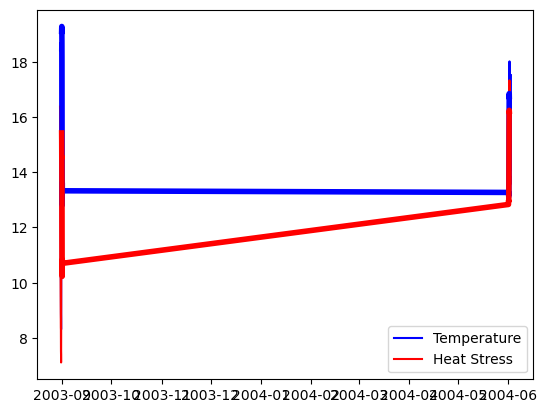

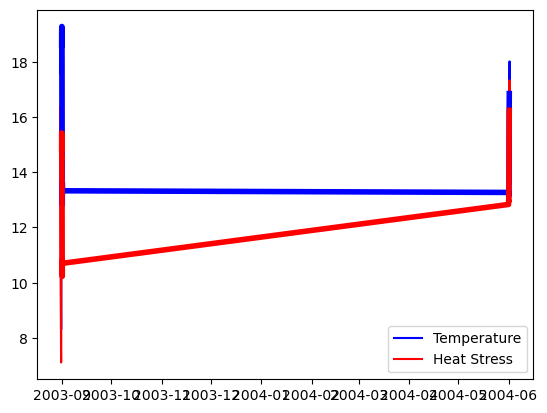

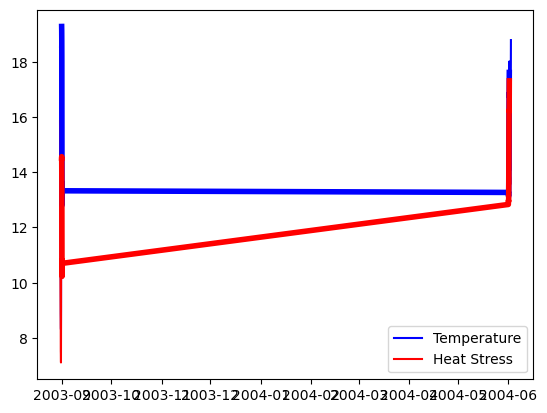

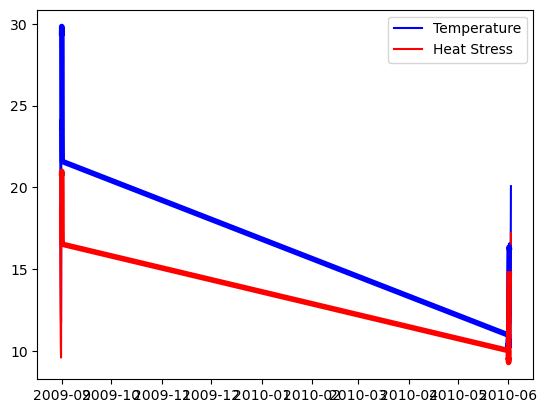

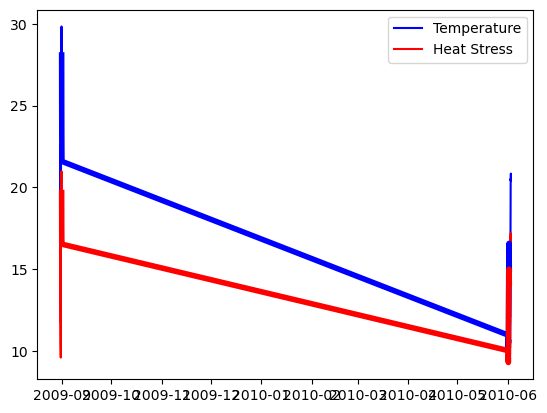

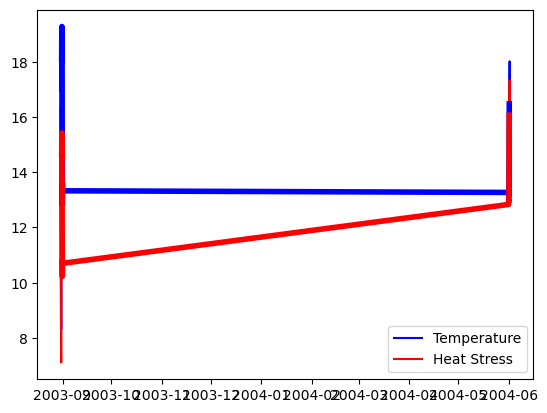

In [61]:
idx = k_minimum_indices(similarities, k)
ind = np.nanargmin(similarities)
for i in range(k):
    ind = idx[i]
    
    x = np.arange(ind-24, ind+24+w)
    x1 = np.arange(ind, ind+w)
    
    x = ts_date[ind-24:ind+w+24]
    x1 = ts_date[ind:ind+w]
    
    plt.plot(x, ts_tas[ind-24:ind+w+24], color="blue", label="Temperature")
    plt.plot(x, ts_wbgt[ind-24:ind+w+24], color="red", label="Heat Stress")
    
    plt.plot(x1, ts_tas[ind:ind+w], color="blue", lw=4)
    plt.plot(x1, ts_wbgt[ind:ind+w], color="red", lw=4)
    plt.legend()
    plt.show()

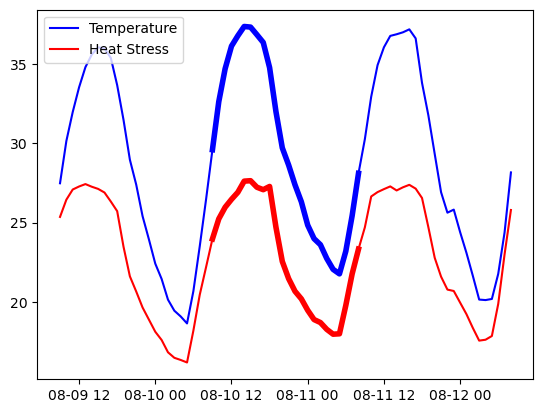

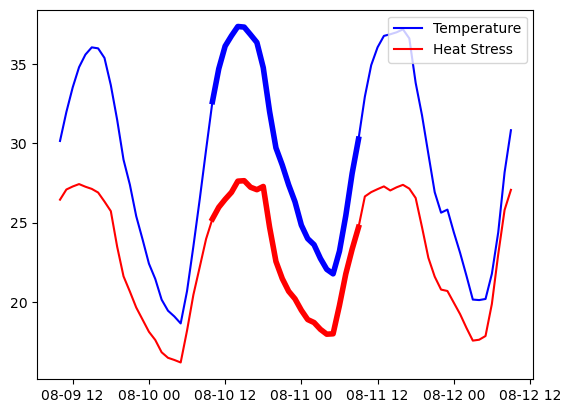

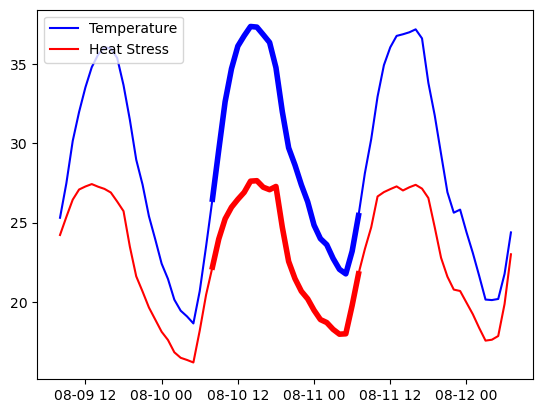

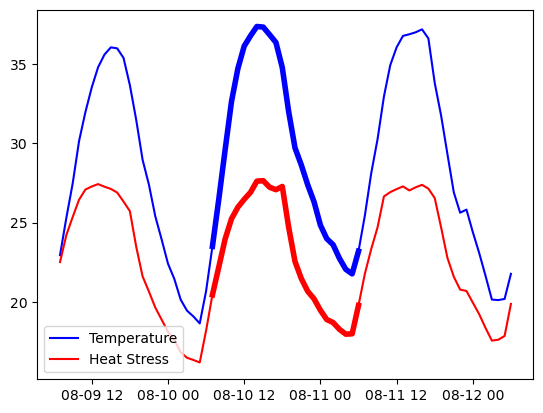

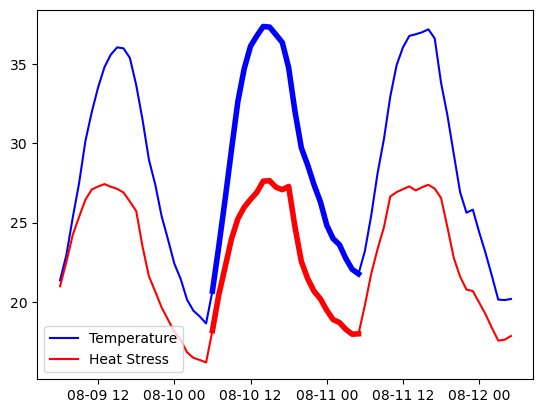

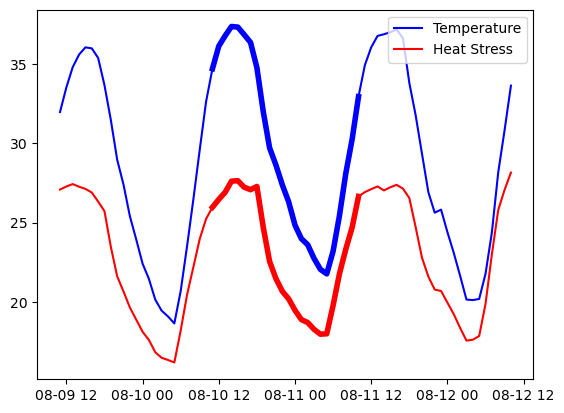

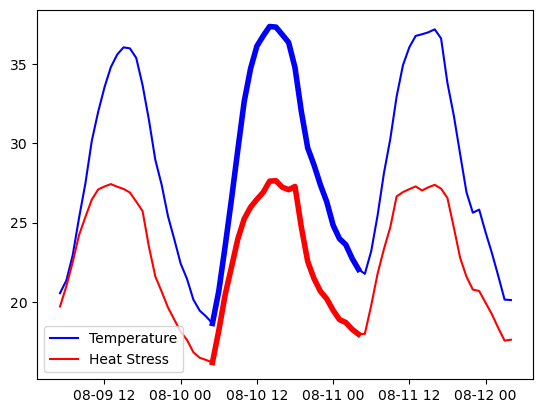

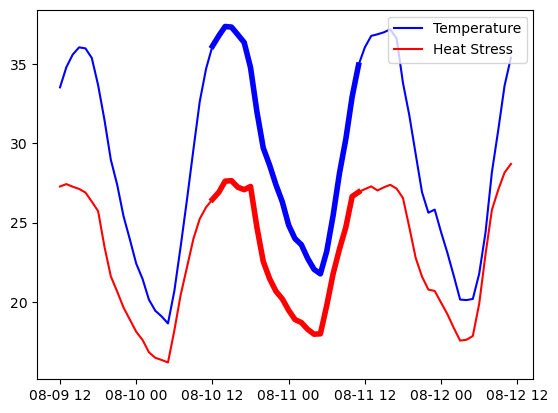

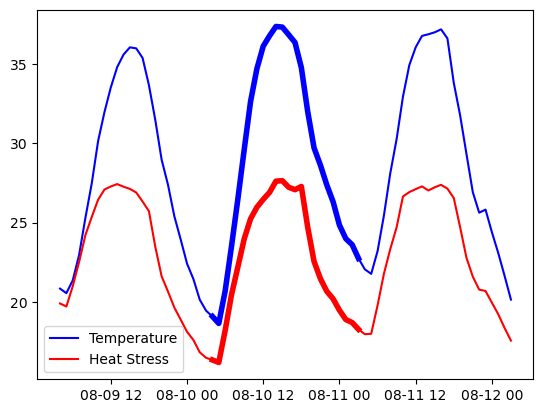

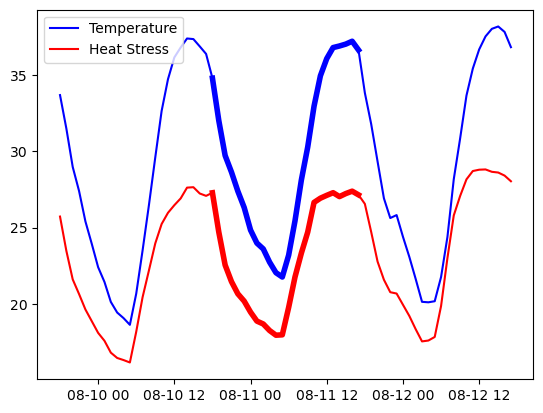

In [62]:
idx = k_minimum_indices(-distances, k)
for i in range(k):
    ind = idx[i]
    
    x = np.arange(ind-24, ind+24+w)
    x1 = np.arange(ind, ind+w)
    
    x = ts_date[ind-24:ind+w+24]
    x1 = ts_date[ind:ind+w]
    
    plt.plot(x, ts_tas[ind-24:ind+w+24], color="blue", label="Temperature")
    plt.plot(x, ts_wbgt[ind-24:ind+w+24], color="red", label="Heat Stress")
    
    plt.plot(x1, ts_tas[ind:ind+w], color="blue", lw=4)
    plt.plot(x1, ts_wbgt[ind:ind+w], color="red", lw=4)
    plt.legend()
    plt.show()